In [1]:
import os, json, time, hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

REPO_URL = "https://github.com/Mugdha-Naik/deepfake-detector-project.git"
REPO_DIR = "/kaggle/working/repo"
if not os.path.exists(REPO_DIR):
    os.system(f"git clone {REPO_URL} {REPO_DIR}")
INPUT_ROOT = "/kaggle/input"
OUT = "/kaggle/working/p2_10"
os.makedirs(OUT, exist_ok=True)

SEED, N_BOOT = 2026, 1000
MIN_FACES, MIN_VIDEOS = 30, 10
K_PRIMARY = 20
CONF_MIN = 0.8                 # "confident" faces, fixed in Step 2.7

def find_one(name, roots):
    for root in roots:
        matches = [os.path.join(d, name) for d, _, fs in os.walk(root) if name in fs]
        if len(matches) == 1:
            return matches[0]
        if len(matches) > 1:
            raise RuntimeError(f"{name}: {len(matches)} copies under {root}. Attach only one:\n" + "\n".join(matches))
    raise FileNotFoundError(f"{name} not found under {roots}")
ROOTS = [INPUT_ROOT, REPO_DIR]
print("setup OK")

Cloning into '/kaggle/working/repo'...


setup OK


In [2]:
# ============================================================
# FREEZE THE RULE (runs before anything is computed). Do not edit after the first run.
# ============================================================
RULE = {
    "name": "Reliability rule v1 (Trusted / Flagged)",
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "primary": {"faithful": f"faith_{K_PRIMARY} > 0 (faithfulness score, k={K_PRIMARY}%, zero fill, Step 2.7)",
                "stable": "cosine(map, twin map) > p95 of the direction-matched random-pair floor (Step 2.8, above_floor_matched == 1)",
                "trusted": "faithful AND stable; otherwise Flagged; a face with no stability value is Flagged"},
    "variants_defined_in_advance": {
        "faith_only": "faithful only", "stab_only": "stable only",
        "faith_margin": f"faith_{K_PRIMARY} > 0.05 AND stable (guards against noise from only 5 random masks per face)",
        "stab_lenient": "faithful AND cosine above the direction-matched floor MEDIAN (p50)"},
    "constants": {"k_primary": K_PRIMARY, "faith_min": 0.0, "faith_margin": 0.05, "confident_p0": CONF_MIN, "min_faces": MIN_FACES, "min_videos": MIN_VIDEOS, "bootstrap": N_BOOT},
    "reporting": "Trusted share per condition, predicted class and outcome with video-bootstrap CIs; accuracy of Trusted vs Flagged within predicted class; sensitivity variants next to the primary rule; no variant is chosen after seeing results",
    "disclosure": "Rule follows the form suggested in the Phase 2 plan. At the time of writing, aggregate results of Steps 2.7, 2.8 and 2.9 had been seen by the team; the Trusted share had not been computed.",
    "frozen_before_trusted_share_computed": True}
RULE["sha256_of_rule_text"] = hashlib.sha256(json.dumps({k: v for k, v in RULE.items() if k != "sha256_of_rule_text"}, sort_keys=True).encode()).hexdigest()
json.dump(RULE, open(os.path.join(OUT, "rule_frozen.json"), "w"), indent=2)
T_FROZEN = RULE["created_utc"]
print("RULE FROZEN at", T_FROZEN, "UTC | hash", RULE["sha256_of_rule_text"][:12])
print(json.dumps(RULE["primary"], indent=2))

RULE FROZEN at 2026-11-07T17:35:27+00:00 UTC | hash 3af50ed5a3ab
{
  "faithful": "faith_20 > 0 (faithfulness score, k=20%, zero fill, Step 2.7)",
  "stable": "cosine(map, twin map) > p95 of the direction-matched random-pair floor (Step 2.8, above_floor_matched == 1)",
  "trusted": "faithful AND stable; otherwise Flagged; a face with no stability value is Flagged"
}


In [3]:
# ============================================================
# LOAD INPUTS, CHECK THEY BELONG TOGETHER, BUILD ONE TABLE PER CONDITION
# ============================================================
fa_meta = json.load(open(find_one("faithfulness_meta.json", ROOTS)))
st_meta = json.load(open(find_one("stability_meta.json", ROOTS)))
g_meta = json.load(open(find_one("gradcam_meta.json", ROOTS)))
for name, m in (("faithfulness", fa_meta), ("stability", st_meta)):
    assert m["model_sha256"] == g_meta["model_sha256"], f"{name} was made with a different checkpoint"
    assert m["manifest_sha256"] == g_meta["manifest_sha256"], f"{name} was made with a different manifest"
    assert abs(m["threshold"] - 0.2217) < 5e-4, f"{name}: threshold is not the frozen 0.2217"
assert fa_meta["k_primary"] == K_PRIMARY

matched = pd.read_csv(find_one("stability_floor_direction_matched.csv", ROOTS))
matched = matched[matched["direction"].isin(["FAKE->FAKE", "FAKE->REAL", "REAL->FAKE", "REAL->REAL"])]
p50 = {(r.pair, r.direction): r.floor_p50 for r in matched.itertuples()}

stab, F = {}, {}
for clean, comp in (("A", "B"), ("C", "D")):
    s = pd.read_csv(find_one(f"stability_{clean}_{comp}.csv", ROOTS)); s["pair_id"] = s["pair_id"].astype(str); s["face_id"] = s["face_id"].astype(str)
    assert "above_floor_matched" in s.columns, "stability file lacks above_floor_matched: use the RE-RUN Step 2.8 output (with the matched floor)"
    s["floor_p50"] = [p50.get((f"{clean}->{comp}", d_), np.nan) for d_ in s["direction"]]
    stab[clean] = s.set_index("pair_id"); stab[comp] = s.set_index("face_id")

for k in "ABCD":
    d = pd.read_csv(find_one(f"faithfulness_{k}.csv", ROOTS)); d["face_id"] = d["face_id"].astype(str)
    assert d["face_id"].is_unique and (d["cond"] == k).all(), f"{k}: faithfulness file is not one row per face of this condition"
    d = d[["face_id", "video_id", "outcome", "target", "p0", f"faith_{K_PRIMARY}"]].copy(); d["cond"] = k
    s = stab[k]
    for col in ("cos", "direction", "above_floor_matched", "floor_p50", "flip_target"):
        d[col if col != "cos" else "stab_cos"] = d["face_id"].map(s[col])
    d["pred_class"] = np.where(d["outcome"].isin(["TP", "FP"]), "FAKE", "REAL")
    d["correct"] = d["outcome"].isin(["TP", "TN"]).astype(float)
    assert d["outcome"].isin(["TP", "FP", "FN", "TN"]).all(), f"{k}: unknown outcome label"
    assert d["direction"].notna().mean() > 0.99, f"{k}: stability is missing for many faces (wrong stability file?)"
    F[k] = d
    print(f"{k}: {len(d)} faces, {d['video_id'].nunique()} videos | accuracy {d['correct'].mean():.3f} | faces without a stability value: {int(d['stab_cos'].isna().sum())}")
print("inputs OK | threshold", g_meta["threshold"], "| manifest", g_meta["manifest_sha256"][:8])

A: 5883 faces, 198 videos | accuracy 0.839 | faces without a stability value: 0
B: 5883 faces, 198 videos | accuracy 0.527 | faces without a stability value: 0
C: 8763 faces, 300 videos | accuracy 0.646 | faces without a stability value: 1
D: 8763 faces, 300 videos | accuracy 0.538 | faces without a stability value: 1
inputs OK | threshold 0.22168749570846558 | manifest 80eae250


In [4]:
# ============================================================
# STATISTICS FUNCTIONS
# ============================================================
def boot_mean_ci(d, col, n_boot=N_BOOT, seed=SEED):
    d = d.dropna(subset=[col])
    if len(d) == 0: return (np.nan, np.nan, np.nan)
    g = d.groupby("video_id")[col].agg(["sum", "count"]).to_numpy(float)
    if len(g) < 2: return (float(d[col].mean()), np.nan, np.nan)
    rng = np.random.default_rng(seed); idx = rng.integers(0, len(g), size=(n_boot, len(g)))
    means = g[idx, 0].sum(1) / g[idx, 1].sum(1)
    return float(g[:, 0].sum() / g[:, 1].sum()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

def compare(d1, d2, col, rng):
    """group1 - group2 with a joint video bootstrap, effect sizes and a Mann-Whitney test on per-video means."""
    a, b = d1.dropna(subset=[col]), d2.dropna(subset=[col])
    if len(a) < 2 or len(b) < 2: return None
    row = {"n1": len(a), "n2": len(b), "v1": a["video_id"].nunique(), "v2": b["video_id"].nunique(), "mean1": float(a[col].mean()), "mean2": float(b[col].mean())}
    row["diff"] = row["mean1"] - row["mean2"]
    vids = np.union1d(a["video_id"].unique(), b["video_id"].unique()); ix = pd.Index(vids)
    def per(d):
        i = ix.get_indexer(d["video_id"]); return np.bincount(i, weights=d[col].to_numpy(float), minlength=len(vids)), np.bincount(i, minlength=len(vids))
    (s1, c1), (s2, c2) = per(a), per(b)
    idx = rng.integers(0, len(vids), (N_BOOT, len(vids))); n1, n2 = c1[idx].sum(1), c2[idx].sum(1)
    with np.errstate(all="ignore"):
        diffs = np.where((n1 > 0) & (n2 > 0), s1[idx].sum(1) / n1 - s2[idx].sum(1) / n2, np.nan)
    row["ci_lo"], row["ci_hi"] = (float(x) for x in np.nanpercentile(diffs, [2.5, 97.5]))
    g1, g2 = a.groupby("video_id")[col].mean(), b.groupby("video_id")[col].mean()
    if len(g1) >= 3 and len(g2) >= 3:
        r = stats.mannwhitneyu(g1, g2, alternative="two-sided"); row["prob_sup_video"] = float(r.statistic / (len(g1) * len(g2))); row["p_video"] = float(r.pvalue)
    else:
        row["prob_sup_video"], row["p_video"] = np.nan, np.nan
    return row

def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj
print("functions ready")

functions ready


In [5]:
# ============================================================
# APPLY THE FROZEN RULE TO EVERY FACE
# ============================================================
T_ANALYSIS = datetime.now(timezone.utc).isoformat(timespec="seconds")
fcol = f"faith_{K_PRIMARY}"; frames = []
for k, d in F.items():
    d["faithful"] = d[fcol] > RULE["constants"]["faith_min"]
    d["stable"] = d["above_floor_matched"].fillna(0).astype(float) == 1.0
    d["stable_lenient"] = (d["stab_cos"] > d["floor_p50"]).fillna(False)
    d["trusted_primary"] = d["faithful"] & d["stable"]
    d["trusted_faith_only"] = d["faithful"]
    d["trusted_stab_only"] = d["stable"]
    d["trusted_faith_margin"] = (d[fcol] > RULE["constants"]["faith_margin"]) & d["stable"]
    d["trusted_stab_lenient"] = d["faithful"] & d["stable_lenient"]
    d["no_stability"] = d["stab_cos"].isna()
    d["confident"] = d["p0"] >= CONF_MIN
    frames.append(d)
faces = pd.concat(frames, ignore_index=True)
keep = ["face_id", "cond", "video_id", "outcome", "pred_class", "correct", "p0", "confident", fcol, "stab_cos", "direction", "faithful", "stable", "stable_lenient",
        "trusted_primary", "trusted_faith_only", "trusted_stab_only", "trusted_faith_margin", "trusted_stab_lenient", "no_stability"]
faces[keep].to_csv(os.path.join(OUT, "reliability_faces.csv"), index=False)
print(faces.groupby("cond")[["faithful", "stable", "trusted_primary"]].mean().round(3))

      faithful  stable  trusted_primary
cond                                   
A        0.645   0.136            0.085
B        0.766   0.136            0.104
C        0.439   0.105            0.054
D        0.776   0.105            0.079


In [6]:
# ============================================================
# TRUSTED SHARE: per condition, predicted class and outcome (+ sensitivity variants)
# ============================================================
VARIANT_COLS = {"primary": "trusted_primary", "faith_only": "trusted_faith_only", "stab_only": "trusted_stab_only",
                "faith_margin": "trusted_faith_margin", "stab_lenient": "trusted_stab_lenient"}
GROUPS = {"ALL": None, "predicted FAKE": ("pred_class", "FAKE"), "predicted REAL": ("pred_class", "REAL"), "TP": ("outcome", "TP"), "FP": ("outcome", "FP"),
          "FN": ("outcome", "FN"), "TN": ("outcome", "TN"), f"confident (p0>={CONF_MIN})": ("confident", True)}
rows = []
for k in "ABCD":
    d = F[k]
    for g, spec in GROUPS.items():
        sub = d if spec is None else d[d[spec[0]] == spec[1]]
        for vname, col in VARIANT_COLS.items():
            t = sub.assign(_x=sub[col].astype(float)); m, lo, hi = boot_mean_ci(t, "_x")
            rows.append({"cond": k, "group": g, "variant": vname, "trusted_share": m, "ci_lo": lo, "ci_hi": hi, "n_faces": len(sub), "n_videos": sub["video_id"].nunique(),
                         "descriptive_only": len(sub) < MIN_FACES or sub["video_id"].nunique() < MIN_VIDEOS})
share = pd.DataFrame(rows); share.to_csv(os.path.join(OUT, "reliability_summary.csv"), index=False)
prim = share[(share["variant"] == "primary") & share["group"].isin(["ALL", "predicted FAKE", "predicted REAL", "TP", "FP", "FN", "TN"])]
print("PRIMARY RULE: Trusted share (95% CI over videos)\n", prim[["cond", "group", "trusted_share", "ci_lo", "ci_hi", "n_faces", "n_videos"]].round(3).to_string(index=False))
allv = share[(share["group"] == "ALL")].pivot(index="cond", columns="variant", values="trusted_share").round(3)
print("\nSensitivity variants, all faces:\n", allv)

PRIMARY RULE: Trusted share (95% CI over videos)
 cond          group  trusted_share  ci_lo  ci_hi  n_faces  n_videos
   A            ALL          0.085  0.068  0.103     5883       198
   A predicted FAKE          0.017  0.010  0.025     2685       148
   A predicted REAL          0.142  0.117  0.172     3198       155
   A             TP          0.017  0.010  0.026     2368        98
   A             FP          0.019  0.004  0.035      317        50
   A             FN          0.027  0.014  0.043      632        59
   A             TN          0.171  0.141  0.204     2566        96
   B            ALL          0.104  0.085  0.124     5883       198
   B predicted FAKE          0.036  0.021  0.051      591       110
   B predicted REAL          0.111  0.090  0.134     5292       198
   B             TP          0.037  0.018  0.057      405        61
   B             FP          0.032  0.011  0.056      186        49
   B             FN          0.032  0.021  0.044     2595       10

In [7]:
# ============================================================
# ARE TRUSTED FACES MORE OFTEN CORRECT THAN FLAGGED FACES? (within predicted class, because class drives both scores)
# ============================================================
rng = np.random.default_rng(SEED); rows = []
for k in "ABCD":
    d = F[k]
    for g, cls in (("ALL", None), ("predicted FAKE", "FAKE"), ("predicted REAL", "REAL")):
        sub = d if cls is None else d[d["pred_class"] == cls]
        t, f = sub[sub["trusted_primary"]], sub[~sub["trusted_primary"]]
        r = compare(t, f, "correct", rng)
        if r is None:
            rows.append({"cond": k, "group": g, "n_trusted": len(t), "n_flagged": len(f), "descriptive_only": True}); continue
        r.update({"cond": k, "group": g, "n_trusted": len(t), "n_flagged": len(f), "accuracy_trusted": r["mean1"], "accuracy_flagged": r["mean2"],
                  "descriptive_only": min(r["n1"], r["n2"]) < MIN_FACES or min(r["v1"], r["v2"]) < MIN_VIDEOS,
                  "confound_note": "mixes predicted classes" if cls is None else ""})
        rows.append(r)
acc = pd.DataFrame(rows)
tm = (~acc["descriptive_only"].astype(bool)) & acc["p_video"].notna()
acc["p_holm"] = np.nan; acc.loc[tm, "p_holm"] = holm(acc.loc[tm, "p_video"]); acc["n_comparisons_tested"] = int(tm.sum())
acc["reading"] = np.where(acc["descriptive_only"].astype(bool), "descriptive only", np.where(acc["p_holm"] < 0.05, "differs (Holm p<0.05)", "no clear difference"))
acc.to_csv(os.path.join(OUT, "reliability_accuracy.csv"), index=False)
print("comparisons tested:", int(tm.sum()))
print(acc[["cond", "group", "n_trusted", "n_flagged", "accuracy_trusted", "accuracy_flagged", "diff", "ci_lo", "ci_hi", "p_holm", "reading"]].round(3).to_string(index=False))

comparisons tested: 11
cond          group  n_trusted  n_flagged  accuracy_trusted  accuracy_flagged   diff  ci_lo  ci_hi  p_holm               reading
   A            ALL        501       5382             0.954             0.828  0.126  0.091  0.160   0.000 differs (Holm p<0.05)
   A predicted FAKE         46       2639             0.870             0.882 -0.013 -0.156  0.086   0.326   no clear difference
   A predicted REAL        455       2743             0.963             0.776  0.187  0.130  0.246   0.000 differs (Holm p<0.05)
   B            ALL        610       5273             0.856             0.489  0.366  0.306  0.423   0.000 differs (Holm p<0.05)
   B predicted FAKE         21        570             0.714             0.684  0.030 -0.177  0.213     NaN      descriptive only
   B predicted REAL        589       4703             0.861             0.466  0.395  0.323  0.457   0.003 differs (Holm p<0.05)
   C            ALL        477       8286             0.778             0.

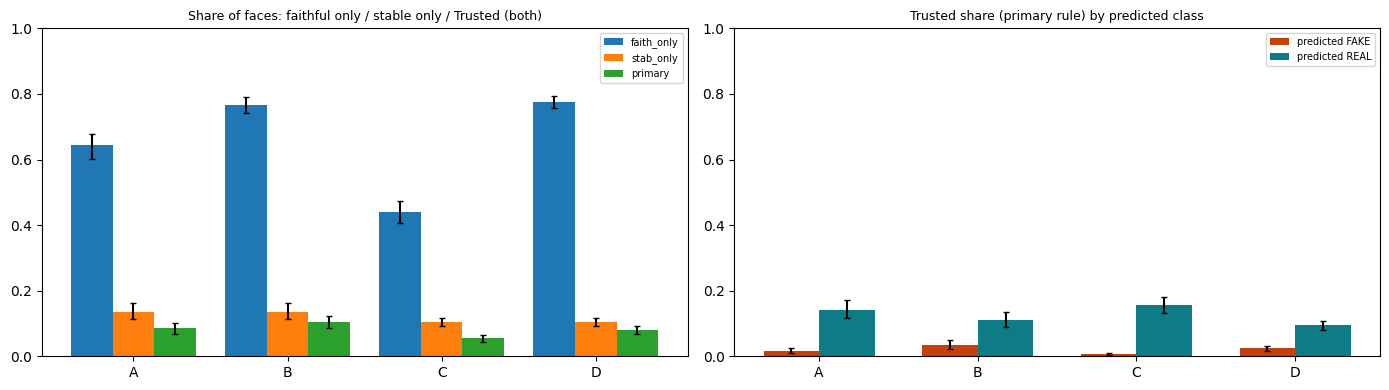

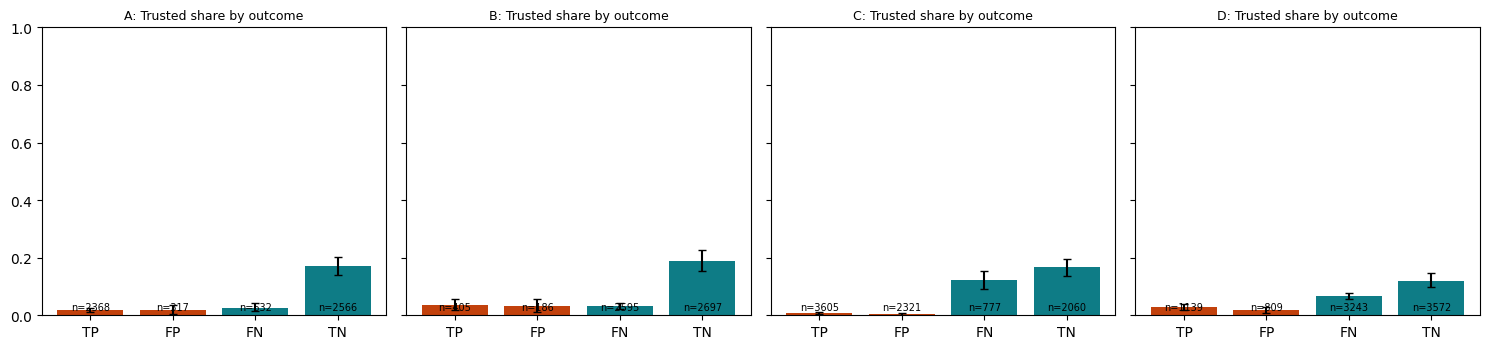

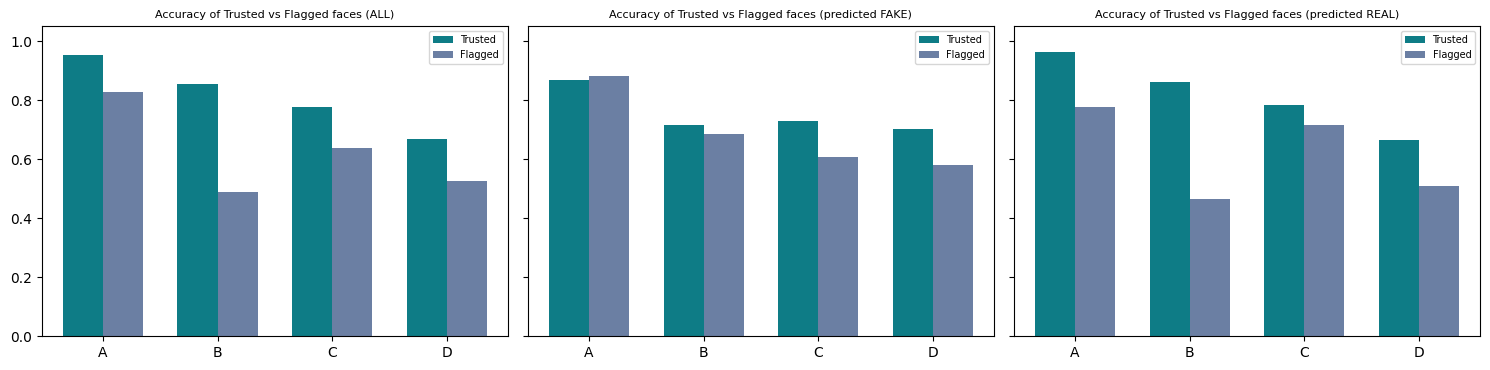

In [8]:
# ============================================================
# FIGURES
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
s = share[(share["group"] == "ALL") & share["variant"].isin(["faith_only", "stab_only", "primary"])]
for i, v in enumerate(["faith_only", "stab_only", "primary"]):
    t = s[s["variant"] == v].set_index("cond").loc[list("ABCD")]
    axes[0].bar(np.arange(4) + (i - 1) * 0.27, t["trusted_share"], 0.27, yerr=[t["trusted_share"] - t["ci_lo"], t["ci_hi"] - t["trusted_share"]], capsize=2, label=v)
axes[0].set_xticks(range(4)); axes[0].set_xticklabels(list("ABCD")); axes[0].set_ylim(0, 1); axes[0].legend(fontsize=7); axes[0].set_title("Share of faces: faithful only / stable only / Trusted (both)", fontsize=9)
for i, g in enumerate(["predicted FAKE", "predicted REAL"]):
    t = share[(share["variant"] == "primary") & (share["group"] == g)].set_index("cond").loc[list("ABCD")]
    axes[1].bar(np.arange(4) + (i - 0.5) * 0.35, t["trusted_share"], 0.35, yerr=[t["trusted_share"] - t["ci_lo"], t["ci_hi"] - t["trusted_share"]], capsize=2, label=g, color=["#C2410C", "#0E7C86"][i])
axes[1].set_xticks(range(4)); axes[1].set_xticklabels(list("ABCD")); axes[1].set_ylim(0, 1); axes[1].legend(fontsize=7); axes[1].set_title("Trusted share (primary rule) by predicted class", fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "trusted_share.png"), dpi=130); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, k in zip(axes, "ABCD"):
    t = share[(share["variant"] == "primary") & (share["cond"] == k) & share["group"].isin(["TP", "FP", "FN", "TN"])].set_index("group").loc[["TP", "FP", "FN", "TN"]]
    ax.bar(t.index, t["trusted_share"], yerr=[(t["trusted_share"] - t["ci_lo"]).fillna(0), (t["ci_hi"] - t["trusted_share"]).fillna(0)], capsize=3, color=["#C2410C", "#C2410C", "#0E7C86", "#0E7C86"])
    for i, (g, r) in enumerate(t.iterrows()): ax.text(i, 0.02, f"n={int(r['n_faces'])}", ha="center", fontsize=7)
    ax.set_ylim(0, 1); ax.set_title(f"{k}: Trusted share by outcome", fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "trusted_by_outcome.png"), dpi=130); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, g in zip(axes, ["ALL", "predicted FAKE", "predicted REAL"]):
    for i, (col, lab, colr) in enumerate((("accuracy_trusted", "Trusted", "#0E7C86"), ("accuracy_flagged", "Flagged", "#6B7FA3"))):
        t = acc[acc["group"] == g].set_index("cond").reindex(list("ABCD"))
        ax.bar(np.arange(4) + (i - 0.5) * 0.35, t[col], 0.35, label=lab, color=colr)
    ax.set_xticks(range(4)); ax.set_xticklabels(list("ABCD")); ax.set_ylim(0, 1.05); ax.set_title(f"Accuracy of Trusted vs Flagged faces ({g})", fontsize=8); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "trusted_accuracy.png"), dpi=130); plt.show()

In [9]:
# ============================================================
# CHECKS + METADATA
# ============================================================
checks = []
frozen = json.load(open(os.path.join(OUT, "rule_frozen.json")))
checks.append({"check": "rule file written before the analysis started", "value": f"{frozen['created_utc']} <= {T_ANALYSIS}", "limit": "frozen <= analysis", "pass": frozen["created_utc"] <= T_ANALYSIS})
checks.append({"check": "rule hash unchanged", "value": frozen["sha256_of_rule_text"][:12], "limit": RULE["sha256_of_rule_text"][:12], "pass": frozen["sha256_of_rule_text"] == RULE["sha256_of_rule_text"]})
for k, d in F.items():
    checks += [{"check": f"{k}: Trusted is a subset of faithful and of stable", "value": int(d["trusted_primary"].sum()), "limit": "<= each criterion",
                "pass": bool((d["trusted_primary"] <= d["faithful"]).all() and (d["trusted_primary"] <= d["stable"]).all())},
               {"check": f"{k}: every face has a label", "value": len(d), "limit": len(d), "pass": bool(d["trusted_primary"].notna().all())},
               {"check": f"{k}: faces without a stability value (flagged)", "value": int(d["no_stability"].sum()), "limit": "informational", "pass": True}]
checks.append({"check": "shares are valid probabilities", "value": f"{share['trusted_share'].min():.3f}..{share['trusted_share'].max():.3f}", "limit": "0..1", "pass": bool(share["trusted_share"].between(0, 1).all())})
checks.append({"check": "number of comparisons in the Holm family", "value": int(tm.sum()), "limit": "informational", "pass": True})
checks = pd.DataFrame(checks); checks.to_csv(os.path.join(OUT, "reliability_checks.csv"), index=False); print(checks.to_string(index=False))
json.dump({"created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "rule_frozen_at": T_FROZEN, "rule_sha256": RULE["sha256_of_rule_text"], "model_sha256": g_meta["model_sha256"],
           "manifest_sha256": g_meta["manifest_sha256"], "threshold": g_meta["threshold"], "variants": list(VARIANT_COLS), "constants": RULE["constants"],
           "n_faces": {k: len(d) for k, d in F.items()}, "n_comparisons_tested": int(tm.sum()), "seed": SEED, "disclosure": RULE["disclosure"]}, open(os.path.join(OUT, "reliability_meta.json"), "w"), indent=2)
print("\nsaved:", sorted(os.listdir(OUT)))
assert checks["pass"].all(), "AN INTEGRITY CHECK FAILED: do not start Step 2.11 until this is understood."
print("Done. Next: Step 2.11 consolidation (master table, README, tag phase2-v1). Do NOT change the rule now.")

                                           check                                                  value              limit  pass
   rule file written before the analysis started 2026-11-07T17:35:27+00:00 <= 2026-11-07T17:35:30+00:00 frozen <= analysis  True
                             rule hash unchanged                                           3af50ed5a3ab       3af50ed5a3ab  True
A: Trusted is a subset of faithful and of stable                                                    501  <= each criterion  True
                       A: every face has a label                                                   5883               5883  True
    A: faces without a stability value (flagged)                                                      0      informational  True
B: Trusted is a subset of faithful and of stable                                                    610  <= each criterion  True
                       B: every face has a label                                                 